In [1]:
%load_ext autoreload
%autoreload 2

In [13]:
from pathlib import Path
import sys
import html as html_lib
from IPython.display import HTML, display as ipy_display
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns


root = Path.cwd().resolve()
root = root.parent
sys.path.insert(0, str(root))

import torch
from collections import defaultdict
from transformers import AutoTokenizer, AutoModelForCausalLM
from sae_trainer.core.model_utils import SparseAutoencoder, ReluSparseAutoencoder, TopKSparseAutoencoder
from sae_trainer.sae_semantic_eval.feature_tracer_utils import FeatureTracer, TraceConfig
from sae_trainer.sae_semantic_eval.feature_tracer_eval_utils import (
    search_features_by_concept, 
    build_query_feature_matrix,
    build_query_feature_matrix, 
    compare_query_differences,
    render_feature_card,
    build_query_feature_matrix, 
    compare_query_differences, 
    explain_difference_similarity,
    top_n_feats_by_hits_count, 
    top_n_feats_by_act_mass, 
    prompt_x_feature_heatmap, 
    feature_token_position_profile, 
    top_m_feature_coactivation, 
    render_feature_card, 
    plot_feature_umap, 
    plot_inter_feature_similarity, 
    plot_feature_similarity_violins
)



In [3]:
#device = "cuda" if torch.cuda.is_available() else "cpu"
device = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"device: {device}")
layer_idx = 12
dataset_name = 'openwebtext'
model_name_simple = "qwen" # Either gpt2 or qwen
sae_type = 'topk'
k = 40

if model_name_simple == "gpt2":
    model_name = "gpt2"
elif model_name_simple == "qwen":
    model_name = "Qwen/Qwen2-0.5B-Instruct"
else:
    raise ValueError(f"Invalid model name: {model_name_simple}. Expected either 'gpt2' or 'qwen'.")
tokenizer = AutoTokenizer.from_pretrained(model_name)
llm = AutoModelForCausalLM.from_pretrained(model_name).to(device).eval()

# Load SAE checkpoint — pick whichever layer you want to analyse (3, 6, 9, or 11)
ckpt = torch.load(root / f"model_weights_files/{sae_type}_sae_{model_name_simple}_{dataset_name}_layer{layer_idx}.pt", map_location=device)
if sae_type == 'relu':
    sae = ReluSparseAutoencoder(d_in=ckpt["d_in"], d_latent=ckpt["d_latent"], normalize_decoder=True).to(device)
elif sae_type == 'topk':
    sae = TopKSparseAutoencoder(d_in=ckpt["d_in"], d_latent=ckpt["d_latent"], k=k, normalize_decoder=True).to(device)
else:
    raise ValueError(f"Invalid sae type: {sae_type}. Expected either 'relu' or 'qwen'.")
sae.load_state_dict(ckpt["model_state"])
sae.eval()

device: mps


TopKSparseAutoencoder(
  (encoder): Linear(in_features=896, out_features=7168, bias=True)
  (decoder): Linear(in_features=7168, out_features=896, bias=False)
)

In [4]:
# 4) Tracer config — layer_idx MUST match the checkpoint loaded above
cfg = TraceConfig(
    layer_idx=layer_idx,
    topk_per_token=8,
    min_activation=0.01,
    max_new_tokens=50,
    do_sample=True,
    temperature=0.7,
    token_mode='generated_only',
    min_prompts=5
)
tracer = FeatureTracer(llm, tokenizer, sae, device, cfg)

In [5]:
from datasets import load_dataset

n_train_docs = 4000 # cfg.max_batches * cfg.collection_batch_size

ds = load_dataset("openwebtext", split="train", streaming=True)
# Exclude training data
ds = ds.skip(n_train_docs)

summaries = tracer.trace_prompts_from_iterable_dataset(ds, max_prompts_to_trace=750)

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/transformers/pytorch_utils.py:325: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_elements = torch.tensor(test_elements)


In [6]:
# Score all features (calls compute_feature_embeddings internally)
scores = tracer.feature_specificity_scores()
#display(scores.head(20))

In [7]:
# Get some new feature ids to test

# Find features related to a concept
results = search_features_by_concept(
    "Good",
    tracer=tracer,
    top_n=10,
    search_by="context",   # surrounding text semantics
)
display(results)

,feature_id,score,context_sim,token_sim,hits,mean_activation
0,3881,0.575603,0.575603,0.505080,687,2.693067
1,1378,0.563516,0.563516,0.391546,389,2.540374
2,5461,0.549623,0.549623,0.423903,444,3.133922
3,1562,0.549586,0.549586,0.520134,785,3.271785
4,2671,0.516861,0.516861,0.528634,657,2.502392
5,726,0.515610,0.515610,0.513113,855,2.702287
6,4560,0.513133,0.513133,0.581320,1083,3.202060
7,3030,0.469807,0.469807,0.611245,3505,3.367490
8,1288,0.464930,0.464930,0.641894,6818,2.875256
9,934,0.461344,0.461344,0.638574,1566,3.949684


In [8]:
#render_feature_card(6269, tracer)

In [9]:

queries = [
    "mathematical reasoning",
    "logical deduction",
    "creative writing",
    "factual recall",
]

feature_matrix, sim_matrix = build_query_feature_matrix(queries, tracer)

# feature_matrix: (4, n_features) — each row is a query's SAE fingerprint
# sim_matrix:     (4, 4)          — pairwise similarity between queries

pd.DataFrame(sim_matrix, index=queries, columns=queries).round(3)


,mathematical reasoning,logical deduction,creative writing,factual recall
mathematical reasoning,1.000,0.824,-0.809,-0.899
logical deduction,0.824,1.000,-0.838,-0.897
creative writing,-0.809,-0.838,1.000,0.640
factual recall,-0.899,-0.897,0.640,1.000


In [10]:
queries = [
    "King",
    "Queen",
    "Aunt",
    "Uncle",
]

feature_matrix, sim_matrix = build_query_feature_matrix(queries, tracer)

# feature_matrix: (4, n_features) — each row is a query's SAE fingerprint
# sim_matrix:     (4, 4)          — pairwise similarity between queries

pd.DataFrame(sim_matrix, index=queries, columns=queries).round(3)

,King,Queen,Aunt,Uncle
King,1.000,0.065,-0.875,0.172
Queen,0.065,1.000,-0.140,-0.708
Aunt,-0.875,-0.140,1.000,-0.411
Uncle,0.172,-0.708,-0.411,1.000


In [11]:
queries = [
    "Good",
    "Great",
    "Bad",
    "Terrible",
]

feature_matrix, sim_matrix = build_query_feature_matrix(queries, tracer)

# feature_matrix: (4, n_features) — each row is a query's SAE fingerprint
# sim_matrix:     (4, 4)          — pairwise similarity between queries

pd.DataFrame(sim_matrix, index=queries, columns=queries).round(3)

,Good,Great,Bad,Terrible
Good,1.000,0.771,-0.893,-0.904
Great,0.771,1.000,-0.929,-0.924
Bad,-0.893,-0.929,1.000,0.884
Terrible,-0.904,-0.924,0.884,1.000


<Axes: >

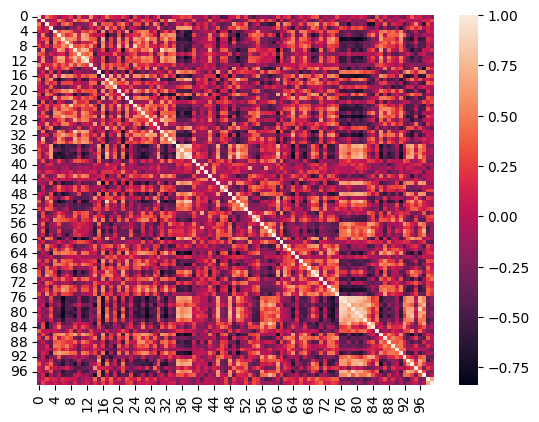

In [95]:
raw_queries = [
    'Sadness',
    'Anger',
    'Happiness',
    'Fear',
    'Surprise',
    'Disgust',
    'Pride',
    'Gratefulness',
    'Longing for',
    'Despise',
    'Despair',
    'Shame',
    'Guilt',
    'Disappointment',
    'Pleasure',
    'Nervousness',
    'Winning',
    'Losing',
    'Succeeding',
    'Failing',
    'Wanting',
    'Craving',
    'Waiting',
    'Inhibiting',
    'Social longing',
    'Speaking',
    'Laughing',
    'Love',
    'Social exclusion',
    'Togetherness',
    'Loneliness',
    'Ostracism',
    'Closeness (in social relations)',
    'Hostility',
    'Sympathy',
    'Anxiety',
    'Panic',
    'Stress',
    'Depression',
    'Mania',
    'Eating',
    'Drinking',
    'Hunger',
    'Satiation',
    'Thirst',
    'Sweating',
    'Urinating',
    'Defecation',
    'Tiredness',
    'Vitality',
    'Exhaustion',
    'Breathing',
    'Heartbeat',
    'Drunkenness',
    'Sexual arousal',
    'Orgasm',
    'Shivering',
    'Hangover',
    'Heartburn',
    'Suffocation',
    'Relaxation',
    'Sleeping',
    'Thinking',
    'Remembering',
    'Attending',
    'Forgetting',
    'Reading',
    'Imagining',
    'Daydreaming',
    'Inferring',
    'Reasoning',
    'Estimating',
    'Being conscious',
    'Memorizing',
    'Recognition',
    'Recollection',
    'Having flu',
    'Having fever',
    'Having stomach flu',
    'Having cold',
    'Having headache',
    'Feeling nauseous',
    'Having toothache',
    'Coughing',
    'Sneezing',
    'Aching',
    'Being dazzled',
    'Seeing',
    'Hearing',
    'Feeling touch',
    'Smelling',
    'Tasting',
    'Itching',
    'Numbness',
    'Feeling pain',
    'Hotness',
    'Coldness',
    'Dizziness',
    'Movement',
    'Acceleration'
]

queries = [f"Describe the following emotion: {raw_query}" for raw_query in raw_queries]

tracer.compute_feature_embeddings()

feature_matrix, sim_matrix = build_query_feature_matrix(queries, tracer)

# feature_matrix: (n_queries, n_features) — each row is a query's SAE fingerprint
# sim_matrix:     (n_queries, n_queries)          — pairwise similarity between queries

pd.DataFrame(sim_matrix, index=queries, columns=queries).round(3)

sns.heatmap(sim_matrix)

In [29]:
feature_matrix.shape

(100, 7168)

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


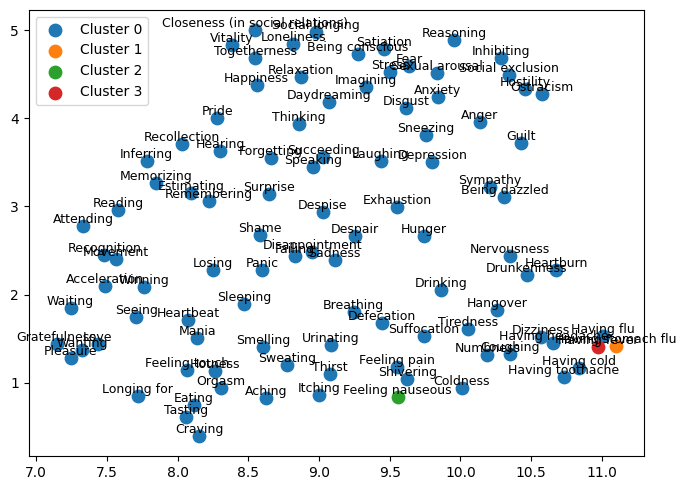

In [16]:
from sklearn.cluster import AgglomerativeClustering
feature_matrix, _ = build_query_feature_matrix(queries, tracer)
labels = AgglomerativeClustering(n_clusters=4, metric="cosine", linkage="average").fit_predict(feature_matrix)

import umap

reducer = umap.UMAP(n_components=2, metric="cosine", random_state=42)
coords = reducer.fit_transform(feature_matrix)

plt.figure(figsize=(7, 5))
for cid in sorted(set(labels)):
    mask = np.array(labels) == cid
    plt.scatter(coords[mask, 0], coords[mask, 1], label=f"Cluster {cid}", s=80)
for i, q in enumerate(queries):
    plt.annotate(q, coords[i], fontsize=9, ha="center", va="bottom")
plt.legend()
plt.tight_layout()
plt.show()



In [27]:
# Find optimal UMAP intermediate dimensionality

from sklearn.cluster import HDBSCAN
from hdbscan.validity import validity_index
from sklearn.metrics import silhouette_score
import numpy as np

results = []
for n_dim in [2, 3, 5, 8, 10, 15, 20]:
    for min_cluster_size in [3, 5, 8]:
        reducer = umap.UMAP(n_components=n_dim, metric="cosine", random_state=42)
        embedding = reducer.fit_transform(feature_matrix)

        clusterer = HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean")
        labels = clusterer.fit_predict(embedding)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        # DBCV-style validity index — HDBSCAN-native, works with non-convex clusters
        validity = validity_index(embedding.astype("float64"), labels, metric="euclidean")

        results.append({
            "n_dim": n_dim,
            "min_cluster_size": min_cluster_size,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "validity": validity,
        })

for r in results:
    print(r)

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/User

{'n_dim': 2, 'min_cluster_size': 3, 'n_clusters': 13, 'n_noise': 29, 'validity': 0.3147835624423855}
{'n_dim': 2, 'min_cluster_size': 5, 'n_clusters': 5, 'n_noise': 44, 'validity': 0.2020355354248715}
{'n_dim': 2, 'min_cluster_size': 8, 'n_clusters': 2, 'n_noise': 36, 'validity': 0.009798012155445651}
{'n_dim': 3, 'min_cluster_size': 3, 'n_clusters': 10, 'n_noise': 16, 'validity': 0.22897059086867366}
{'n_dim': 3, 'min_cluster_size': 5, 'n_clusters': 3, 'n_noise': 18, 'validity': 0.17452650106052703}
{'n_dim': 3, 'min_cluster_size': 8, 'n_clusters': 4, 'n_noise': 41, 'validity': 0.24886183485036945}
{'n_dim': 5, 'min_cluster_size': 3, 'n_clusters': 9, 'n_noise': 19, 'validity': 0.16314696861742717}
{'n_dim': 5, 'min_cluster_size': 5, 'n_clusters': 5, 'n_noise': 21, 'validity': 0.2027813974103741}
{'n_dim': 5, 'min_cluster_size': 8, 'n_clusters': 3, 'n_noise': 35, 'validity': 0.19624754995169894}
{'n_dim': 8, 'min_cluster_size': 3, 'n_clusters': 10, 'n_noise': 29, 'validity': 0.29031798

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


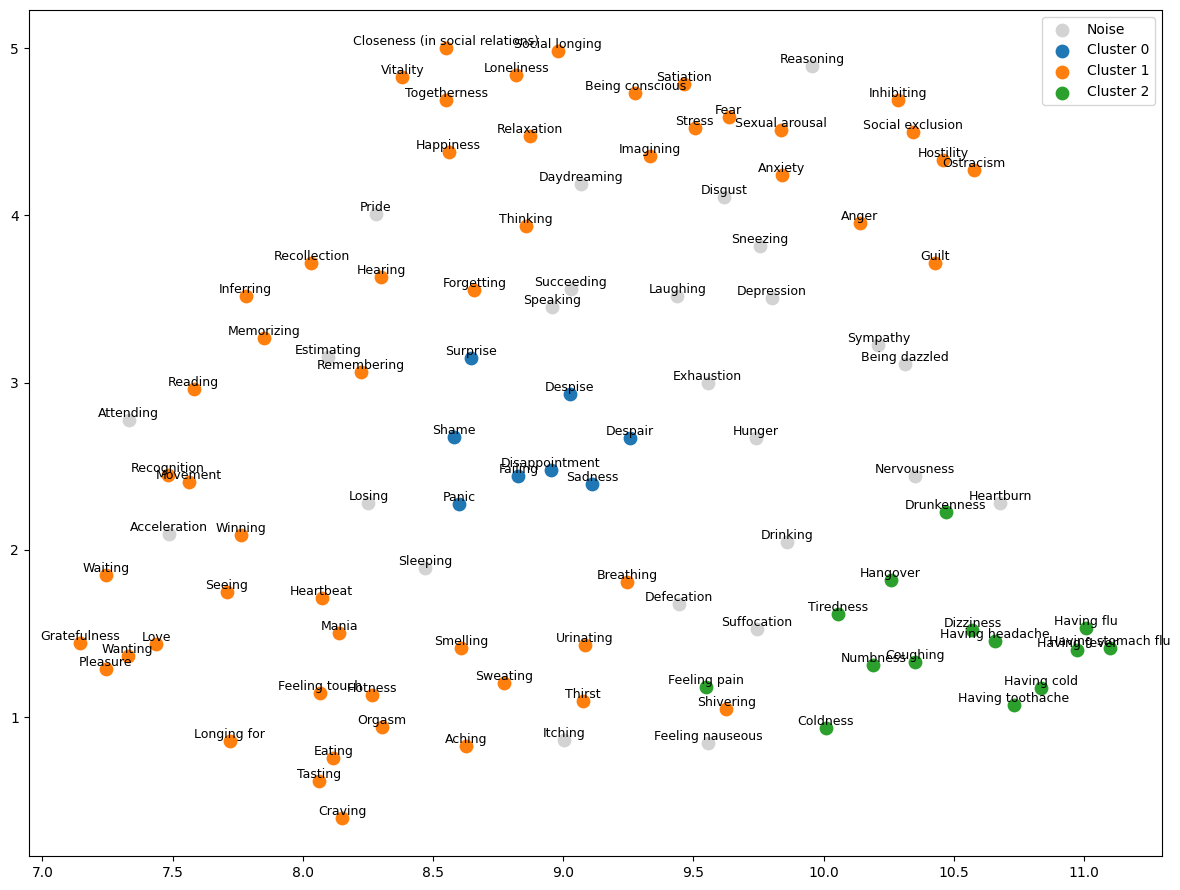

In [28]:
import umap
from sklearn.cluster import HDBSCAN  # or: from hdbscan import HDBSCAN

feature_matrix, _ = build_query_feature_matrix(queries, tracer)

reducer_cluster = umap.UMAP(n_components=15, metric="cosine", random_state=42)
embedding_cluster = reducer_cluster.fit_transform(feature_matrix)

clusterer = HDBSCAN(min_cluster_size=5, metric="euclidean")
labels = clusterer.fit_predict(embedding_cluster)

# For visualization only — separate 2D projection
reducer_viz = umap.UMAP(n_components=2, metric="cosine", random_state=42)
coords = reducer_viz.fit_transform(feature_matrix)

plt.figure(figsize=(12, 9))
for cid in sorted(set(labels)):
    mask = np.array(labels) == cid
    label_name = "Noise" if cid == -1 else f"Cluster {cid}"
    color = "lightgray" if cid == -1 else None
    plt.scatter(coords[mask, 0], coords[mask, 1], label=label_name, s=80, c=color)
for i, q in enumerate(queries):
    plt.annotate(q, coords[i], fontsize=9, ha="center", va="bottom")
plt.legend()
plt.tight_layout()
plt.show()

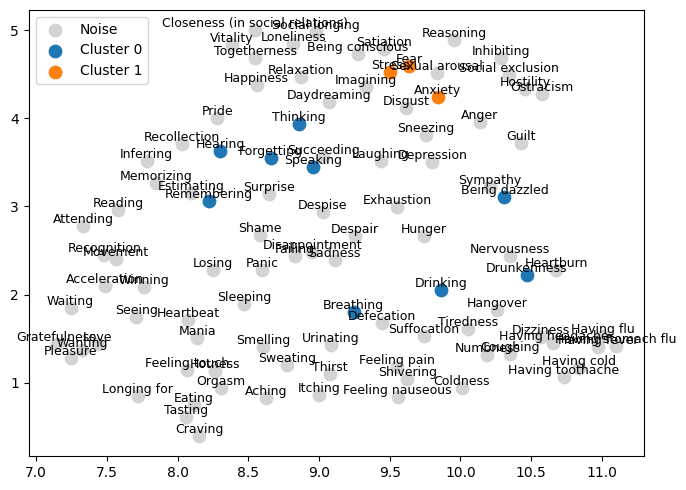

In [18]:
import umap
from sklearn.cluster import HDBSCAN  # or: from hdbscan import HDBSCAN

feature_matrix, _ = build_query_feature_matrix(queries, tracer)

#reducer = umap.UMAP(n_components=2, metric="cosine", random_state=42)
#coords = reducer.fit_transform(feature_matrix)

clusterer = HDBSCAN(min_cluster_size=3, metric="cosine")
labels = clusterer.fit_predict(feature_matrix)

plt.figure(figsize=(7, 5))
for cid in sorted(set(labels)):
    mask = np.array(labels) == cid
    label_name = "Noise" if cid == -1 else f"Cluster {cid}"
    color = "lightgray" if cid == -1 else None
    plt.scatter(coords[mask, 0], coords[mask, 1], label=label_name, s=80, c=color)
for i, q in enumerate(queries):
    plt.annotate(q, coords[i], fontsize=9, ha="center", va="bottom")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

queries = ["King", "Queen", "Aunt", "Uncle"]
feature_matrix, _ = build_query_feature_matrix(queries, tracer)

diff_matrix, labels, sim = compare_query_differences(
    feature_matrix,
    queries,
    pairs=[("King", "Queen"), ("Uncle", "Aunt"), ("King", "Uncle")],
)

pd.DataFrame(sim, index=labels, columns=labels).round(3)


,King → Queen,Uncle → Aunt,King → Uncle
King → Queen,1.000,0.714,-0.019
Uncle → Aunt,0.714,1.000,-0.166
King → Uncle,-0.019,-0.166,1.000


In [ ]:
np.argsort(diff_matrix[0])[-10:]

array([6315,  454, 6480, 5644,  846, 1827,  302,  988, 1292,  135])

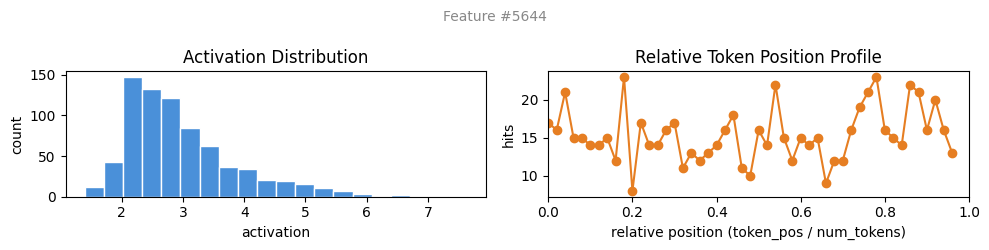

In [40]:
render_feature_card(5644, tracer)

In [44]:

queries = ["King", "Queen", "Aunt", "Uncle"]
feature_matrix, _ = build_query_feature_matrix(queries, tracer)

diff_matrix, labels, sim = compare_query_differences(
    feature_matrix, queries,
    pairs=[("King", "Queen"), ("Uncle", "Aunt")],
)

explain_difference_similarity(
    diff_matrix, labels,
    pair_i="King → Queen",
    pair_j="Uncle → Aunt",
    tracer=tracer,
    top_n=10,
)


,feature_id,contribution,delta_i,delta_j,hits,mean_activation
0,135,0.031759,0.133335,0.156261,110,2.528058
1,2799,0.020014,-0.100137,-0.131119,27,2.191784
2,9,0.013147,-0.086517,-0.099689,706,3.169154
3,3181,0.013131,-0.051587,-0.166991,16,2.263659
4,3293,0.010371,-0.077242,-0.088080,971,4.022112
5,2511,0.010202,-0.065749,-0.101795,157,2.762558
6,2140,0.010175,-0.084827,-0.078690,23,2.851076
7,5050,0.010026,-0.065210,-0.100865,202,2.942247
8,820,0.009244,-0.064791,-0.093597,258,2.543481
9,6542,0.008480,-0.062859,-0.088500,355,3.459678


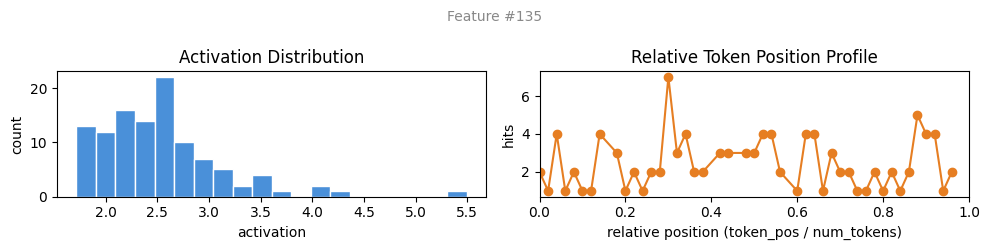

In [50]:
render_feature_card(135, tracer)

In [61]:

queries = ["Good", "Great", "Bad", "Terrible"]
feature_matrix, _ = build_query_feature_matrix(queries, tracer)

diff_matrix, labels, sim = compare_query_differences(
    feature_matrix, queries,
    pairs=[("Good", "Great"), ("Bad", "Terrible")],
)

explain_difference_similarity(
    diff_matrix, labels,
    pair_i="Good → Great",
    pair_j="Bad → Terrible",
    tracer=tracer,
    top_n=10,
)

,feature_id,contribution,delta_i,delta_j,hits,mean_activation
0,6079,0.025923,0.127231,0.047905,226,3.636953
1,6074,0.021667,0.115774,0.044003,99,3.698378
2,1264,0.019546,-0.082370,-0.055793,1,2.586761
3,1902,0.016391,0.081537,0.047267,74,3.874226
4,3435,0.011916,0.075721,0.037001,571,2.762334
5,1244,0.010647,0.079732,0.031397,40,3.100725
6,4010,0.008217,-0.059451,-0.032498,10,2.634809
7,722,0.007994,-0.025417,-0.073953,836,2.698267
8,486,0.007260,0.061147,0.027917,20,2.307578
9,1827,0.006909,0.088672,0.018321,2,2.176037


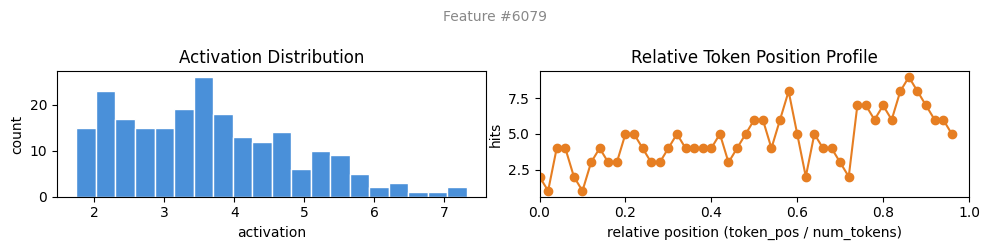

In [62]:
render_feature_card(6079, tracer)

In [96]:
# token_mode="generated_only" means the spectrum reflects only the response,
# not the prompt tokens
config = TraceConfig(layer_idx=layer_idx, token_mode="generated_only", max_new_tokens=50)
tracer = FeatureTracer(llm, tokenizer, sae, device, config)
tracer.trace_prompts(queries, ids=list(range(len(queries))))


/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/transformers/pytorch_utils.py:325: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  test_elements = torch.tensor(test_elements)


[{'prompt_id': 0,
  'prompt': 'Describe the following emotion: Sadness',
  'generated_text': 'Describe the following emotion: Sadness.\nSadness is a complex emotion that can be experienced in different ways depending on the individual and the context in which it is experienced. It can be a feeling of sadness, which is a deep and intense emotional state of sadness, or it can be',
  'num_prompt_tokens': 7,
  'num_tokens': 57,
  'num_hits': 392},
 {'prompt_id': 1,
  'prompt': 'Describe the following emotion: Anger',
  'generated_text': 'Describe the following emotion: Anger.\nAnger is a strong and intense emotion that can be characterized by a range of physical and emotional reactions. It is often characterized by intense feelings of frustration, anger, and irritation, and can be triggered by a variety of factors, including personal grievances',
  'num_prompt_tokens': 7,
  'num_tokens': 57,
  'num_hits': 392},
 {'prompt_id': 2,
  'prompt': 'Describe the following emotion: Happiness',
  'g

In [97]:
from sae_trainer.sae_semantic_eval.feature_tracer_eval_utils import build_token_feature_spectrum


n_features = sae.d_latent
#spectrum = build_token_feature_spectrum(prompt_id=0, tracer=tracer, n_features=n_features)
#first_token = spectrum.iloc[0]   # first traced token position, as a Series (feature_id → activation)
spectra = {
    query: build_token_feature_spectrum(i, tracer, n_features).iloc[0]
    for i, query in enumerate(queries)
}
# spectra["King"] → DataFrame of shape (n_features, n_stats)
# columns: hits, firing_rate, mean_activation, max_activation, ...


In [98]:
tracer.to_dataframe()

,prompt_id,prompt,generated_text,token_pos,token_pos_relative,num_tokens,num_tokens_relative,token,feature_id,activation
0,0,Describe the following emotion: Sadness,Describe the following emotion: Sadness.\nSadn...,7,0,57,50,.Ċ,96,4.934071
1,0,Describe the following emotion: Sadness,Describe the following emotion: Sadness.\nSadn...,7,0,57,50,.Ċ,4902,4.253925
2,0,Describe the following emotion: Sadness,Describe the following emotion: Sadness.\nSadn...,7,0,57,50,.Ċ,2671,3.694288
3,0,Describe the following emotion: Sadness,Describe the following emotion: Sadness.\nSadn...,7,0,57,50,.Ċ,6741,3.041184
4,0,Describe the following emotion: Sadness,Describe the following emotion: Sadness.\nSadn...,7,0,57,50,.Ċ,6017,2.749989
...,...,...,...,...,...,...,...,...,...,...
39195,99,Describe the following emotion: Acceleration,Describe the following emotion: Acceleration\n...,55,48,57,50,Ġand,6527,1.982098
39196,99,Describe the following emotion: Acceleration,Describe the following emotion: Acceleration\n...,55,48,57,50,Ġand,5638,1.961304
39197,99,Describe the following emotion: Acceleration,Describe the following emotion: Acceleration\n...,55,48,57,50,Ġand,3580,1.934013
39198,99,Describe the following emotion: Acceleration,Describe the following emotion: Acceleration\n...,55,48,57,50,Ġand,5698,1.665741


In [99]:
spectra['Describe the following emotion: Sadness']

feature_id
0       0.0
1       0.0
2       0.0
3       0.0
4       0.0
       ... 
7163    0.0
7164    0.0
7165    0.0
7166    0.0
7167    0.0
Name: 7, Length: 7168, dtype: float64

In [100]:
import numpy as np

first_token_matrix = np.stack([
    build_token_feature_spectrum(i, tracer, n_features).iloc[0].values
    for i in range(len(queries))
]).astype(np.float32)  # (n_queries, n_features)



In [101]:
results = []
for n_dim in [2, 3, 5, 8, 10, 15, 20]:
    for min_cluster_size in [3, 5, 8]:
        reducer = umap.UMAP(n_components=n_dim, metric="cosine", random_state=42)
        embedding = reducer.fit_transform(first_token_matrix)

        clusterer = HDBSCAN(min_cluster_size=min_cluster_size, metric="euclidean")
        labels = clusterer.fit_predict(embedding)

        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = list(labels).count(-1)

        # DBCV-style validity index — HDBSCAN-native, works with non-convex clusters
        validity = validity_index(embedding.astype("float64"), labels, metric="euclidean")

        results.append({
            "n_dim": n_dim,
            "min_cluster_size": min_cluster_size,
            "n_clusters": n_clusters,
            "n_noise": n_noise,
            "validity": validity,
        })

for r in results:
    print(r)

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/User

{'n_dim': 2, 'min_cluster_size': 3, 'n_clusters': 10, 'n_noise': 4, 'validity': 0.7071342594353713}
{'n_dim': 2, 'min_cluster_size': 5, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.8755715291543446}
{'n_dim': 2, 'min_cluster_size': 8, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.8755715291543446}
{'n_dim': 3, 'min_cluster_size': 3, 'n_clusters': 9, 'n_noise': 2, 'validity': 0.7816966963273836}
{'n_dim': 3, 'min_cluster_size': 5, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.9228742738457167}
{'n_dim': 3, 'min_cluster_size': 8, 'n_clusters': 4, 'n_noise': 0, 'validity': 0.8874198049129344}
{'n_dim': 5, 'min_cluster_size': 3, 'n_clusters': 9, 'n_noise': 0, 'validity': 0.7850719149004965}
{'n_dim': 5, 'min_cluster_size': 5, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.8930204474442516}
{'n_dim': 5, 'min_cluster_size': 8, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.8930204474442516}
{'n_dim': 8, 'min_cluster_size': 3, 'n_clusters': 5, 'n_noise': 0, 'validity': 0.9419667672817469}
{'n_dim':

/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/alyssagardiner/src/sae_trainer/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


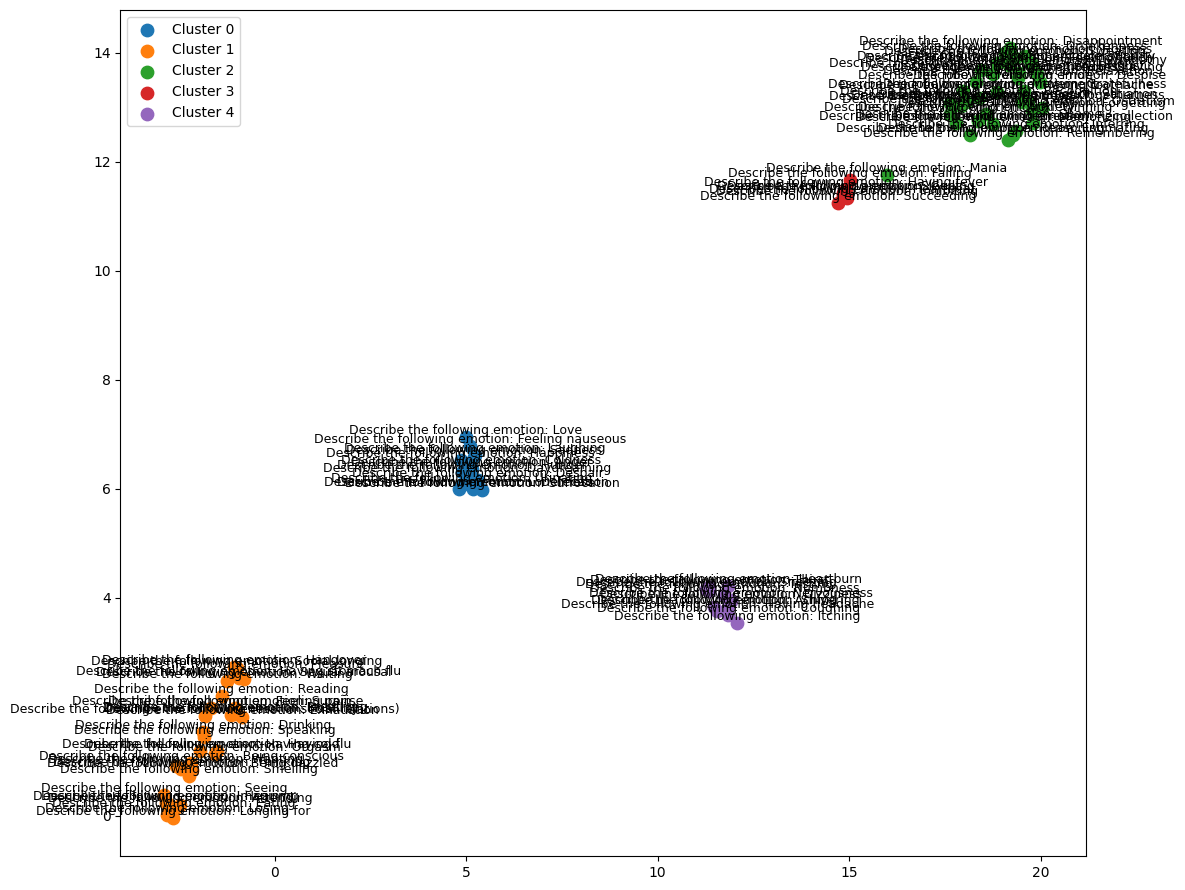

In [102]:
reducer_cluster = umap.UMAP(n_components=8, metric="cosine", random_state=42)
embedding_cluster = reducer_cluster.fit_transform(first_token_matrix)

clusterer = HDBSCAN(min_cluster_size=3, metric="euclidean")
labels = clusterer.fit_predict(embedding_cluster)

# For visualization only — separate 2D projection
reducer_viz = umap.UMAP(n_components=2, metric="cosine", random_state=42)
coords = reducer_viz.fit_transform(first_token_matrix)

plt.figure(figsize=(12, 9))
for cid in sorted(set(labels)):
    mask = np.array(labels) == cid
    label_name = "Noise" if cid == -1 else f"Cluster {cid}"
    color = "lightgray" if cid == -1 else None
    plt.scatter(coords[mask, 0], coords[mask, 1], label=label_name, s=80, c=color)
for i, q in enumerate(queries):
    plt.annotate(q, coords[i], fontsize=9, ha="center", va="bottom")
plt.legend()
plt.tight_layout()
plt.show()

In [103]:
queries_by_label = {}

for query, label in zip(queries, labels):
    if label not in queries_by_label.keys():
        queries_by_label[label] = [query]
    else:
        queries_by_label[label].append(query)
queries_by_label.keys()

dict_keys([0, 2, 1, 3, 4])

In [109]:
queries_by_label[4]

['Describe the following emotion: Nervousness',
 'Describe the following emotion: Thirst',
 'Describe the following emotion: Shivering',
 'Describe the following emotion: Heartburn',
 'Describe the following emotion: Having headache',
 'Describe the following emotion: Coughing',
 'Describe the following emotion: Sneezing',
 'Describe the following emotion: Aching',
 'Describe the following emotion: Tasting',
 'Describe the following emotion: Itching',
 'Describe the following emotion: Numbness',
 'Describe the following emotion: Dizziness']